**Lab 1** for the course of *Selected Topics in Music and Acoustic Engineering* :

***Machine Learning for Audio and Acoustic Engineering***
---

* Student 1: NAME HERE
* Student 2: NAME HERE

# **Before you start**

*   Go to "*File*" --> "*Save a copy in Drive*"
*   Open that copy (might open automatically)
*   Then continue below


**Import libraries**

* We need a number of libraries. Import them once to use throughout the document.

In [2]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")
import librosa, librosa.display
import IPython

# **Lab 1: Basic Audio Processing in Python**

Python is a general-purpose programming language that is popular and easy to use. For new programmers, it is a great choice as a first programming language. In fact, more and more university CS departments are centering their introductory courses around Python.


#### **The Python Tutorial**

If you are new to Python, you can follow this [Python Tutorial](https://docs.python.org/3.8/tutorial/index.html).

For the purposes of this course, be sure you understand the following sections:

Section 3: *An Informal Introduction to Python*

*   numbers: int, float
*   strings
*   lists

Section 4: *More Control Flow Tools*

*   if statements
*   for statements
*   range
*   functions

Section 5: *Data Structures*

*   list comprehensions
*   tuples
*   dictionaries
*   looping techniques


Other resources:

*   [The Hitchhiker's Guide to Python](http://docs.python-guide.org/en/latest/)
*   [SciPy Lecture Notes](http://www.scipy-lectures.org/)
*   [SciPy Lecture Notes](http://www.scipy-lectures.org/)
*   [learnpython.org](https://www.learnpython.org/)


### **Exercise 1**: Basic operations with arrays

Use numpy to do the following array operations:

* Create a row vector v1: $[1,\, 2,\, 3]$ with shape (1,3)

In [27]:
v1 = np.array([1,2,3]).reshape(1,3)
print(v1)
print(v1.shape)

[[1 2 3]]
(1, 3)


Expected output:
```
(1, 3)
```

* Create a column vector v2:  $[1,\, 2,\, 3]^T$

In [28]:
v2 = np.array([1,2,3]).reshape(3,1)
print(v2)
print(v2.shape)

[[1]
 [2]
 [3]]
(3, 1)


Expected output:
```
(3, 1)
```

* Create a matrix M of 3 x 3 of random integer elements:

In [29]:
M = np.random.randint(1,10,size=(3,3))
print(M)

[[3 4 1]
 [1 6 8]
 [2 2 6]]


* Show the first row of M:

In [30]:
print(M[0,:])

[3 4 1]


* Show the first column of M:

In [31]:
print(M[:,0].reshape(-1,1))

[[3]
 [1]
 [2]]


* Perform the matrix product v2 times v1:

In [32]:
print(v2 @ v1)

[[1 2 3]
 [2 4 6]
 [3 6 9]]


* Perform the matrix product v1 times v2:

In [33]:
print(v1 @ v2)

[[14]]


* Perform the element-wise multiplication of v2 and v1, with result having the shape of v2:

In [38]:
print(v2 * v1.T)

[[1]
 [4]
 [9]]


* Perform the element-wise multiplication of v1 and v2, with result having the shape of v1:

In [39]:
print(v1 * v2.T)

[[1 4 9]]


* Generate an array of 20 equally-spaced numbers between 0 and 10:

In [41]:
print(np.linspace(0, 10, 20))

[ 0.          0.52631579  1.05263158  1.57894737  2.10526316  2.63157895
  3.15789474  3.68421053  4.21052632  4.73684211  5.26315789  5.78947368
  6.31578947  6.84210526  7.36842105  7.89473684  8.42105263  8.94736842
  9.47368421 10.        ]


Expected output:
```
[ 0.          0.52631579  1.05263158  1.57894737  2.10526316  2.63157895
  3.15789474  3.68421053  4.21052632  4.73684211  5.26315789  5.78947368
  6.31578947  6.84210526  7.36842105  7.89473684  8.42105263  8.94736842
  9.47368421 10.        ]
```

* Generate an array of numbers going from 0 to 1.5 in steps of 0.2:

In [44]:
print(np.arange(0, 1.5, 0.2))

[0.  0.2 0.4 0.6 0.8 1.  1.2 1.4]


Expected output:
```
array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4])
```

* Generate an array of 13 logarithmically-spaced numbers between 1 and 2 (both included) using the numpy function logspace()

In [46]:
np.logspace(np.log10(1), np.log10(2), 13)

array([1.        , 1.05946309, 1.12246205, 1.18920712, 1.25992105,
       1.33483985, 1.41421356, 1.49830708, 1.58740105, 1.68179283,
       1.78179744, 1.88774863, 2.        ])

Expected output:
```
array([1.        , 1.05946309, 1.12246205, 1.18920712, 1.25992105,
       1.33483985, 1.41421356, 1.49830708, 1.58740105, 1.68179283,
       1.78179744, 1.88774863, 2.        ])
```

* Generate the same array of 13 logarithmically-spaced numbers using fractional powers of 2 (i.e. ```2**...```):


In [48]:
2**np.linspace(0, 1, 13)

array([1.        , 1.05946309, 1.12246205, 1.18920712, 1.25992105,
       1.33483985, 1.41421356, 1.49830708, 1.58740105, 1.68179283,
       1.78179744, 1.88774863, 2.        ])

Expected output:
```
array([1.        , 1.05946309, 1.12246205, 1.18920712, 1.25992105,
       1.33483985, 1.41421356, 1.49830708, 1.58740105, 1.68179283,
       1.78179744, 1.88774863, 2.        ])
```

The generated array divides logarithmically an octave and can be used to generate fundamental frequencies for the pitches:

Index | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12
---| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
Pitch | A | A# | B | C | C# | D | D# | E | F | F# | G | G# | A$_2$  



* Use as a starting fundamental frequency, the one corresponding to A (440 Hz), and generate an array with the fundamental frequencies of each pitch:

In [71]:
f = (440 * np.logspace(np.log10(1), np.log10(2), 13))
print(f)

[440.         466.16376152 493.88330126 523.2511306  554.36526195
 587.32953583 622.25396744 659.25511383 698.45646287 739.98884542
 783.99087196 830.60939516 880.        ]


Expected output:
```
[440.         466.16376152 493.88330126 523.2511306  554.36526195
 587.32953583 622.25396744 659.25511383 698.45646287 739.98884542
 783.99087196 830.60939516 880.        ]
```

### **Exercise 2**: Generation of notes

Assume a sampling frequency of fs = 16000 Hz, and generate a time vector with sampling instants between 0 s and 2 s:

In [61]:
fs = 16000
dur = 2
t = np.arange(0, dur, 1/fs).reshape(1,-1)

print(t)

[[0.0000000e+00 6.2500000e-05 1.2500000e-04 ... 1.9998125e+00
  1.9998750e+00 1.9999375e+00]]


Expected output:
```
[0.0000000e+00 6.2500000e-05 1.2500000e-04 ... 1.9998125e+00 1.9998750e+00
 1.9999375e+00]
```

### Tasks:
* Generate an array containing the envelope shape:

\begin{equation}
  a(t) = Ae^{-t/\tau}
\end{equation}

with $\tau = 0.4$, $A=0.5$ and $t$ corresponding to a given time instant:

In [53]:
A = 0.5
tau = 0.4
a = A * np.exp(-t/tau)

print(f'a = {a}')

a = [0.5        0.49992188 0.49984377 ... 0.00337055 0.00337003 0.0033695 ]


Expected output:
```
a = [0.5        0.49992188 0.49984377 ... 0.00337055 0.00337003 0.0033695 ]
```

* Plot the envelope using Matplotlib:

Text(0.5, 1.0, 'Envelope')

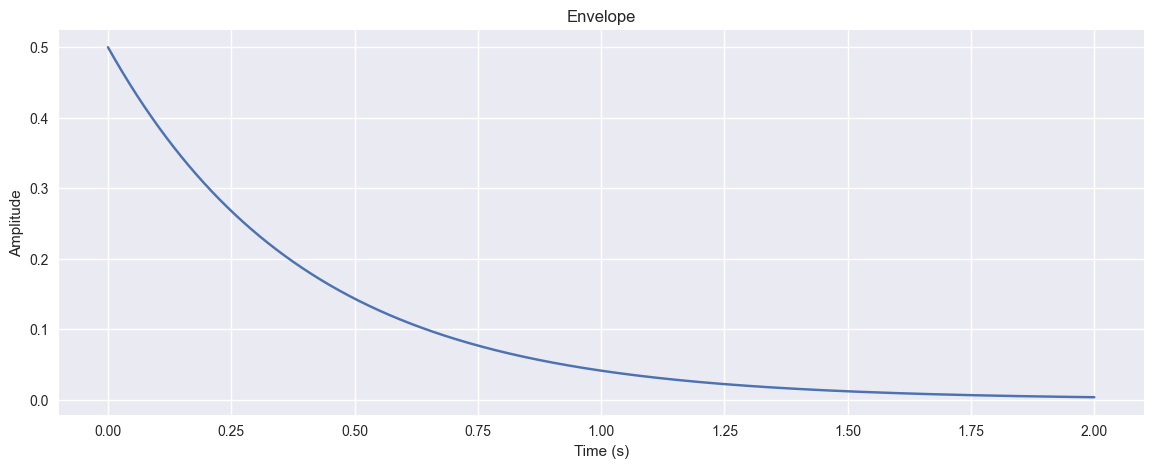

In [54]:
plt.figure(figsize=(14,5))
plt.plot(t, a)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Envelope')

* Generate a sawtooth wave by using ```scipy.signal``` to generates notes with the model

\begin{equation}
  x(t) = a(t) \textrm{sawtooth}(2\pi f_k t)
\end{equation}

where $a(t)$ is the envelope (see above) and $f_k$ the fundamental frequencies of the $k$-th pitch as in the table of Exercise 1.

Generate note signals for pitches A, C#, E and A$_2$:

In [73]:
f_k = np.array([f[0], f[4], f[7], f[12]]).reshape(-1,1)
x = a * signal.sawtooth(2 * np.pi * f_k * t)

* Listen to each of the notes by using ``IPython.display.display(IPython.display.Audio(x, rate=fs))``

In [82]:
for i in range(x.shape[0]):
    IPython.display.display(IPython.display.Audio(x[i,:], rate=fs))

* Generate a vector arpegio by concatenating the four notes:

In [78]:
arpegio = np.concatenate([x[i,:] for i in range(x.shape[0])])
IPython.display.display(IPython.display.Audio(arpegio, rate=fs))

* Generate a vector chord made by summing up the four notes and dividing
them by 4 to avoid clipping:

In [79]:
chord = np.sum(x, axis=0)
IPython.display.display(IPython.display.Audio(chord, rate=fs))

### **Exercise 3**: STFT Representation

Now let's download a speech signal using the wget command. Then, we are going to read it with using ```librosa.load``` and show its sampling rate and duration.

Note 1: The audio file can be also downloaded and imported into you colab space manually.

Note 2: By default, ```librosa.load``` resample the input signal to 22050Hz. If we want to keep the original sampling frequency, then use ```sr=None```.

In [3]:
# !pip install wget
# !wget -P sample_data/ https://www.voiptroubleshooter.com/open_speech/american/OSR_us_000_0010_8k.wav

Sample rate. 8000
Signal duration: 33.623125


Text(0.5, 1.0, 'Signal')

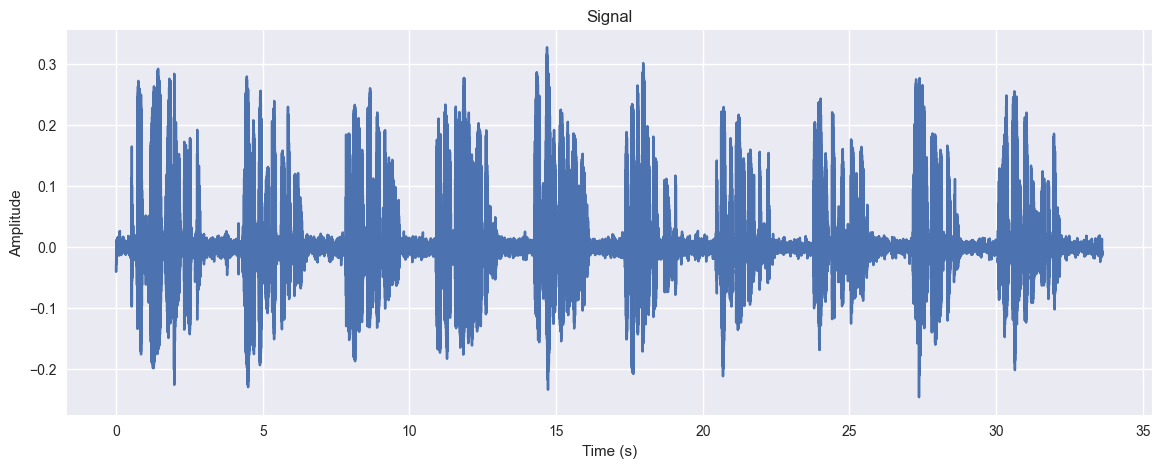

In [10]:
signal, sample_rate = librosa.load('OSR_us_000_0010_8k.wav', sr=None)
print(f'Sample rate. {sample_rate}')
print(f'Signal duration: {signal.shape[0]/sample_rate}')
IPython.display.display(IPython.display.Audio(signal, rate=sample_rate))
plt.figure(figsize=(14,5))
plt.plot(np.arange(0, signal.shape[0]/sample_rate, 1/sample_rate), signal)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Signal')

Expected output:
```
Sample rate:  8000
Signal duration 33.623125
```

### Taks:
* Cut the signal to show only the third spoken sentence (from t=7 s to t = 10 s). Represent it with respect to time in seconds.

Text(0.5, 1.0, 'Signal from $t=7s$ to $t=10s$')

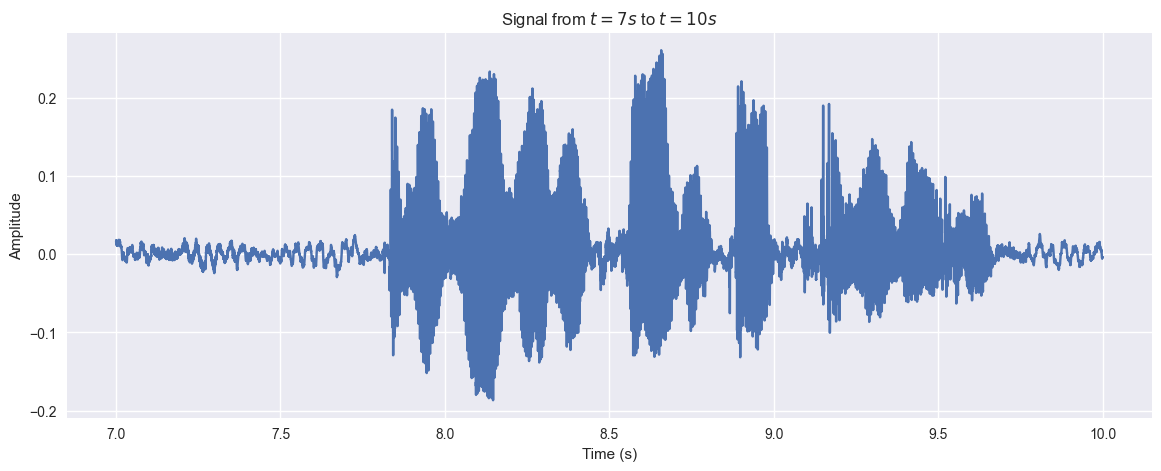

In [7]:
sig = signal[7*sample_rate : 10*sample_rate]
t = np.arange(7, 10, 1/sample_rate)
plt.figure(figsize=(14,5))
plt.plot(t, sig)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Signal from $t=7s$ to $t=10s$')

* Now listen to the selected audio segment:

# CHECK EVERYTHING FROM HERE

In [ ]:
IPython.display.display(IPython.display.Audio(cut_audio, rate=sample_rate))

Create a function "enframe" that takes as input:

*   signal (one-dimensional)
*   frame length (in samples)
*   hop size (in samples)

and returns a matrix where each column stores a frame of the signal. The function should pad the signal with zeroes if necessary.

Here is the pseudocode:



```
FUNCTION enframe(signal, frame_length, hop_size)
    INPUT:
        signal: Array containing the audio signal samples
        frame_length: Integer, the number of samples per frame
        hop_size: Integer, the number of samples to step between frames
    OUTPUT:
        frames: 2D Array where each row is a frame of the signal

    INITIALIZE empty list frames

    CALCULATE total_frames = CEIL((length of signal - frame_length) / hop_size) + 1

    CALCULATE padding_needed = (total_frames - 1) * hop_size + frame_length - length of signal

    IF padding_needed > 0 THEN
        APPEND padding_needed zeros to signal

    FOR i FROM 0 TO total_frames - 1
        START_INDEX = i * hop_size
        END_INDEX = START_INDEX + frame_length

        APPEND signal[START_INDEX:END_INDEX] TO frames

    RETURN frames
END FUNCTION
```

In [ ]:
def enframe(signal, frame_length, hop_size):
    """
    INPUT:
        signal:         Array containing the audio signal samples
        frame_length:   Integer, the number of samples per frame
        hop_size:       Integer, the number of samples to step between frames
    OUTPUT:
        frames:         2D Array where each column is a frame of the signal
    """

    frames = []

    # number of frames that fit into "signal"
    total_frames = np.ceil((len(signal) - frame_length) / hop_size) + 1

    # number of zeros to complete the last frames
    padding_needed = (total_frames - 1) * hop_size + frame_length - len(signal)

    if padding_needed > 0:
        signal = np.append(signal, np.zeros(int(padding_needed)))
    for i in range(int(total_frames)):
        start_index = i * hop_size
        end_index = start_index + frame_length
        # all frame arrays are stored into an array
        frames.append(signal[start_index:end_index])

    # convertion of a list of lists into a matrix and transposition
    # each column is a different frame
    frames = np.vstack(frames).T

    return frames

* Divide the signal into frames of length 512, using a hop size of 256 samples. Show the dimensions of the output.

In [ ]:
frame_length= 512
hop_size = 256
frames = enframe(cut_audio,frame_length,hop_size)
print(np.shape(frames))

Expected output:
```
shape = (512, 93)
```

* Plot the content of the 10-th frame:

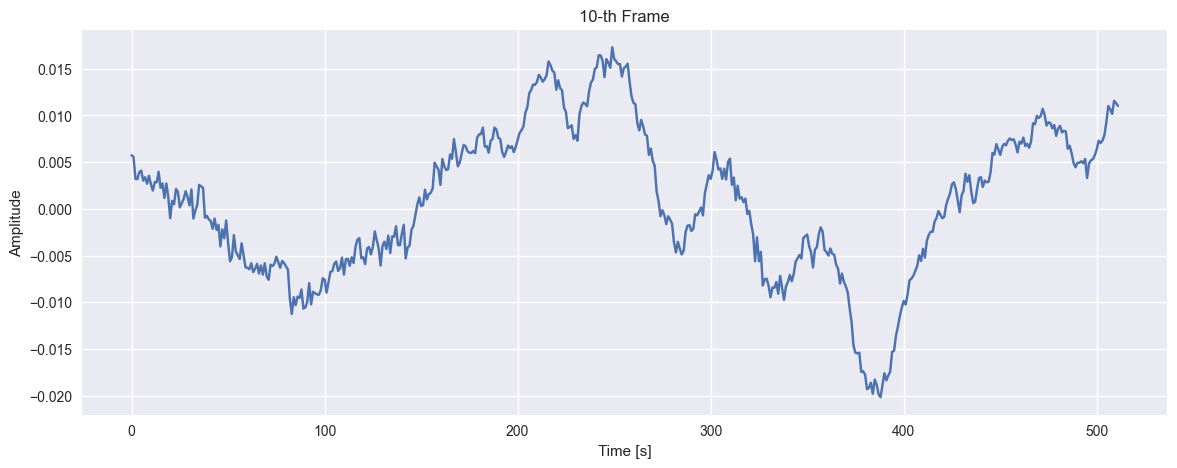

In [ ]:
n_window=11     # number of selected frame
plt.figure(figsize=(14,5))
plt.plot((np.arange(frame_length)+hop_size*(n_window-1))/fs+7,frames[:,n_window-1]) #I'm considering first window it's 1 (index=0), so 10 is asociated with index 9. Of not, delete the -1
plt.title(f'Frame n.° {n_window}')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')

* Create a Hamming function and apply it to each of your frames:

In [ ]:
winfunc = np.hamming(frame_length).reshape(-1, 1)
windowed_signal = frames * winfunc  # smoothing already-cut frames

* Plot again the 10-th frame after having applied your Hamming window:

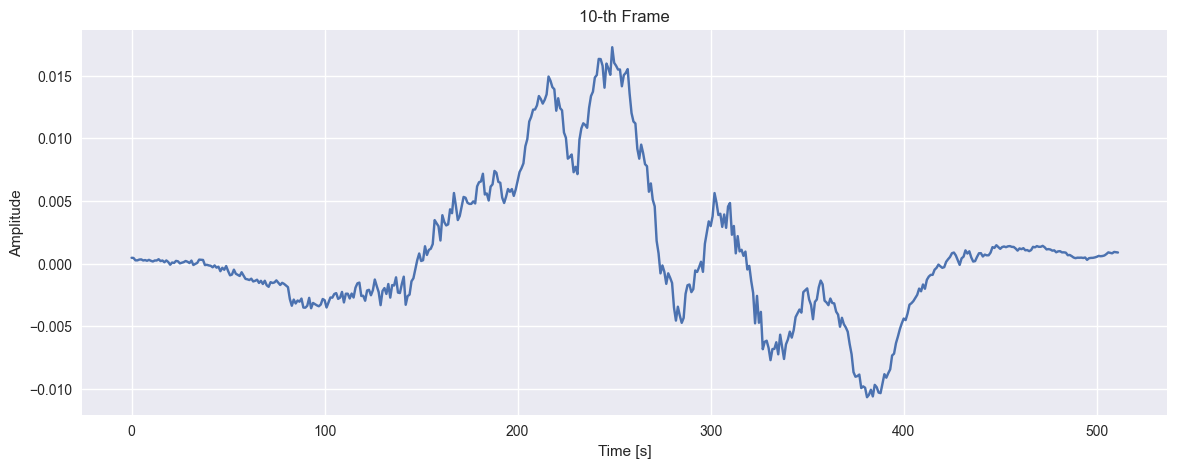

In [ ]:
plt.figure(figsize=(14,5))
plt.plot((np.arange(frame_length)+hop_size*(n_window-1))/fs+7,windowed_signal[:,n_window-1])
plt.title(f'Frame n.° {n_window} with Hamming windowing')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')

* Compute the DFT of each column (frame) using numpy's ```rfft()``` function. Use as number of FFT points the same value as window length.

In [ ]:
NFFT = frame_length     # frame length = window length
DFT=np.fft.rfft(windowed_signal, NFFT,axis=0)   # FFT of each column
print(np.shape(DFT))
# We obtain frame_length//2+1, because the function only take the positive frequencies

* Use the following function to represent the result with the indices of each frame and each frequency bin in the horizontal and vertical axes, respectively.



In [ ]:
def show_specgram(X,ratio,limits,cmin):
  '''This function represents matrix X within a figure having the desired
  aspect ratio.
  Input:
    - X: matrix to represent
    - ratio: aspect ratio of axes
    - limits: array with [xmin, xmax, ymax, ymin] (y axis is reversed)
    - cmin: minimum value corresponding to the bottom of the colormap scale.
  Output:
    - figure handle
  '''
  w, h = plt.figaspect(ratio);
  fig = plt.figure(figsize=(w*2, h*2))
  ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
  im = ax.imshow(X, extent = limits, cmap='viridis', interpolation='none')
  xleft, xright = ax.get_xlim()
  ybottom, ytop = ax.get_ylim()
  ax.set_aspect(abs((xright-xleft)/(ybottom-ytop))*ratio)
  ax.invert_yaxis()
  if cmin != None:
    cbar = plt.colorbar(im)
    cbar.mappable.set_clim(cmin, None)
  return ax

* Now let's use the function ```show_spectrogram```to display the log power spectrogram ```(10*np.log10(np.abs(X)**2)```.

Note: User parameters ratio=0.7 and  cmin=-50

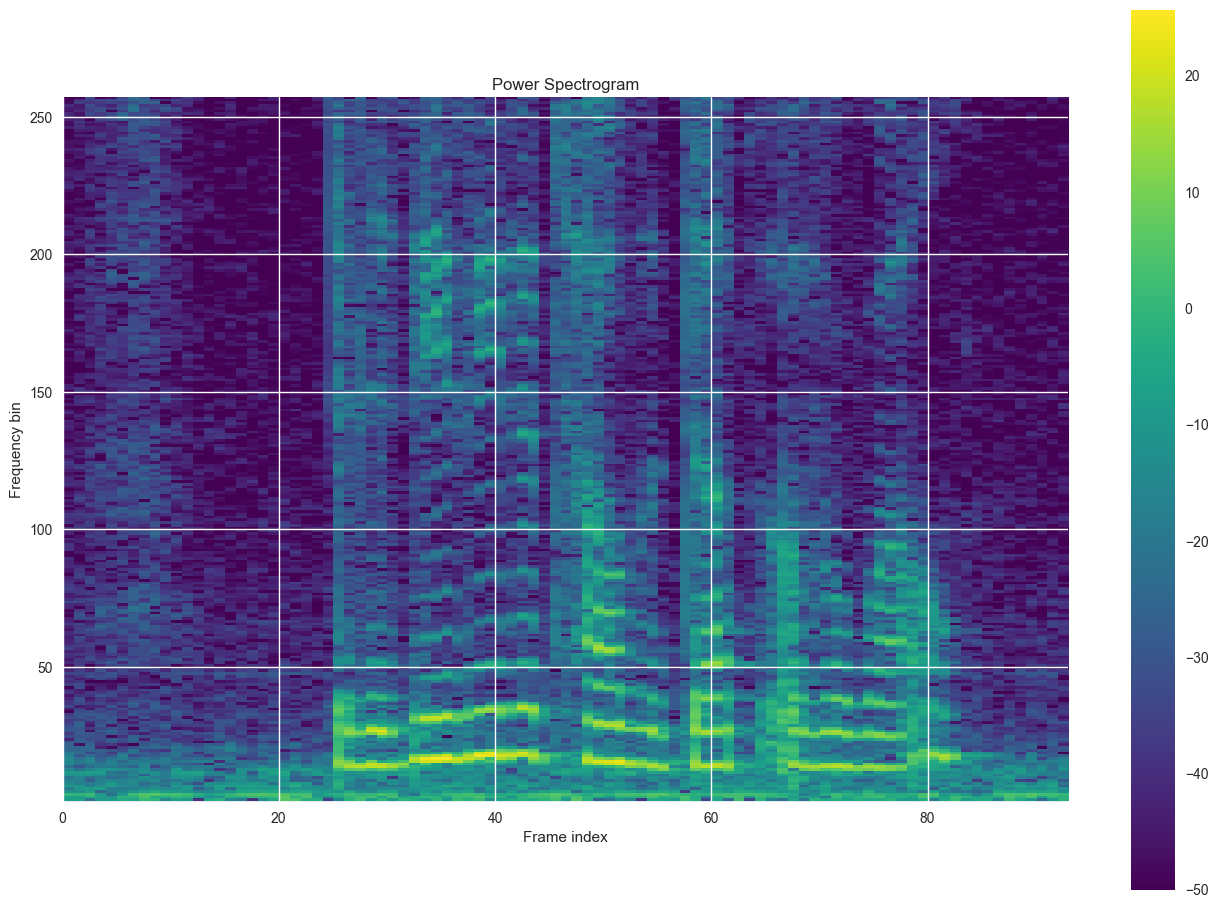

In [ ]:
# plot of spectogram = |FFT{sig}|^2 (in dB)
ax = show_specgram(10*np.log10(np.abs(DFT)**2),ratio=0.7,limits=[0,np.shape(DFT)[1],0,np.shape(DFT)[0]],cmin=-50)
ax.set_title('Power Spectrogram')
ax.set_ylabel('Frequency bin')
ax.set_xlabel('Frame index')

* Finally, represent again the spectrogram but as a function of the time in seconds and frequency in Hz.

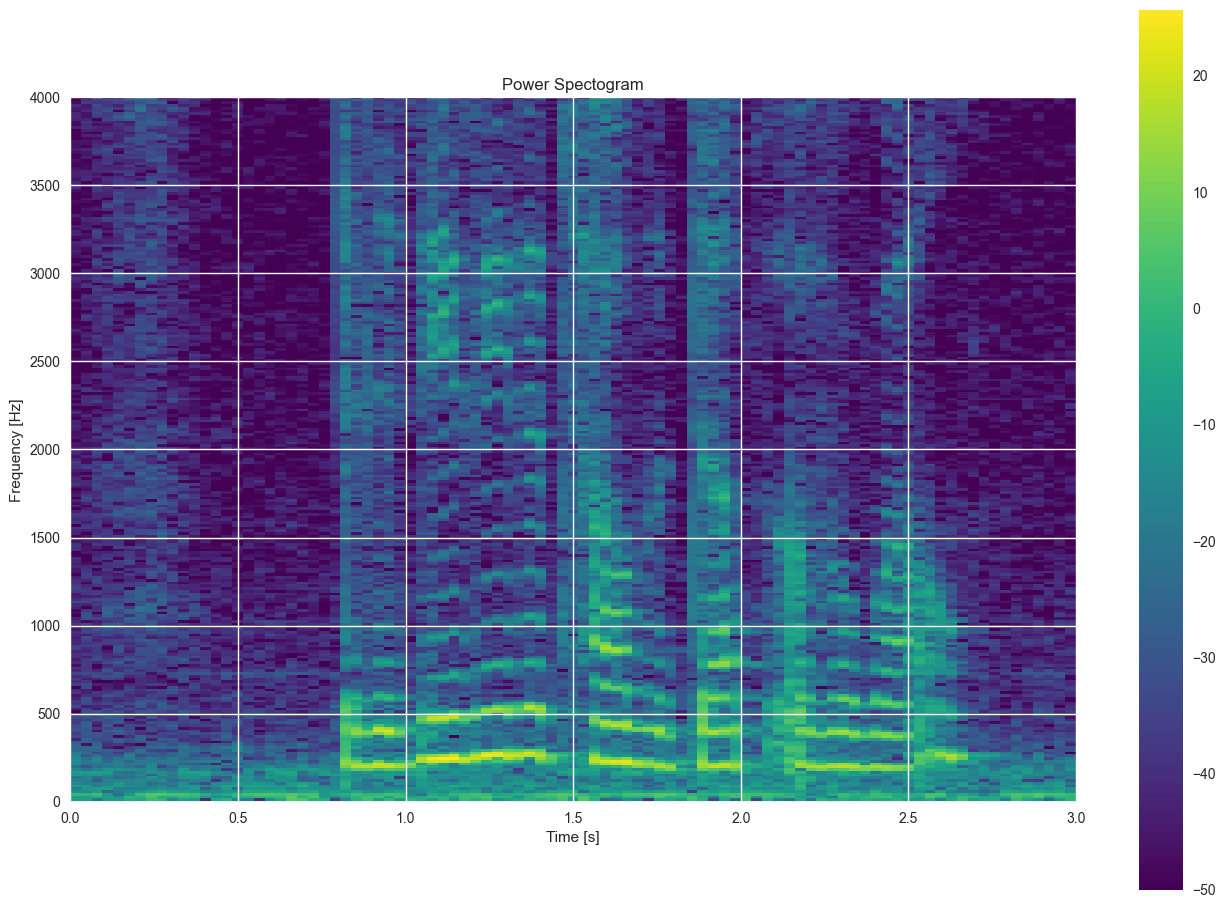

In [ ]:
# spectogram in time [s] and frequency [Hz]
f_bins = np.arange(NFFT//2+1)
time_seconds = np.arange(7,10,hop_size/sample_rate)
ax = show_specgram(10*np.log10(np.abs(DFT)**2),ratio=0.7,limits=[7,10,sample_rate/2,0],cmin=-50)
ax.set_title('Power Spectrogram')
ax.set_ylabel('Frequency [Hz]')
ax.set_xlabel('Time [s]')

### **Exercise 4**: Librosa representations (STFT)

Let's first check the librosa documentation: https://librosa.org/doc/main/generated/librosa.stft.html?highlight=stft#librosa-stft

The most important parameters are:
  - **win_length** - this is the size of our analysis window (in samples)
  - **hop_length** - this is the hop size of our analysis window (in samples), usually this is chosen to be half the window size
  - (**n_fft**) - this is the used "FFT size", which can be bigger than the **win_length** (but should be a power of two, such that the Fast Fourier Transform (FFT) algorithm can be used internally)
  

### Tasks:
* Use librosa to represent the power spectrogram of the signal, as we computed manually in the last exercise.

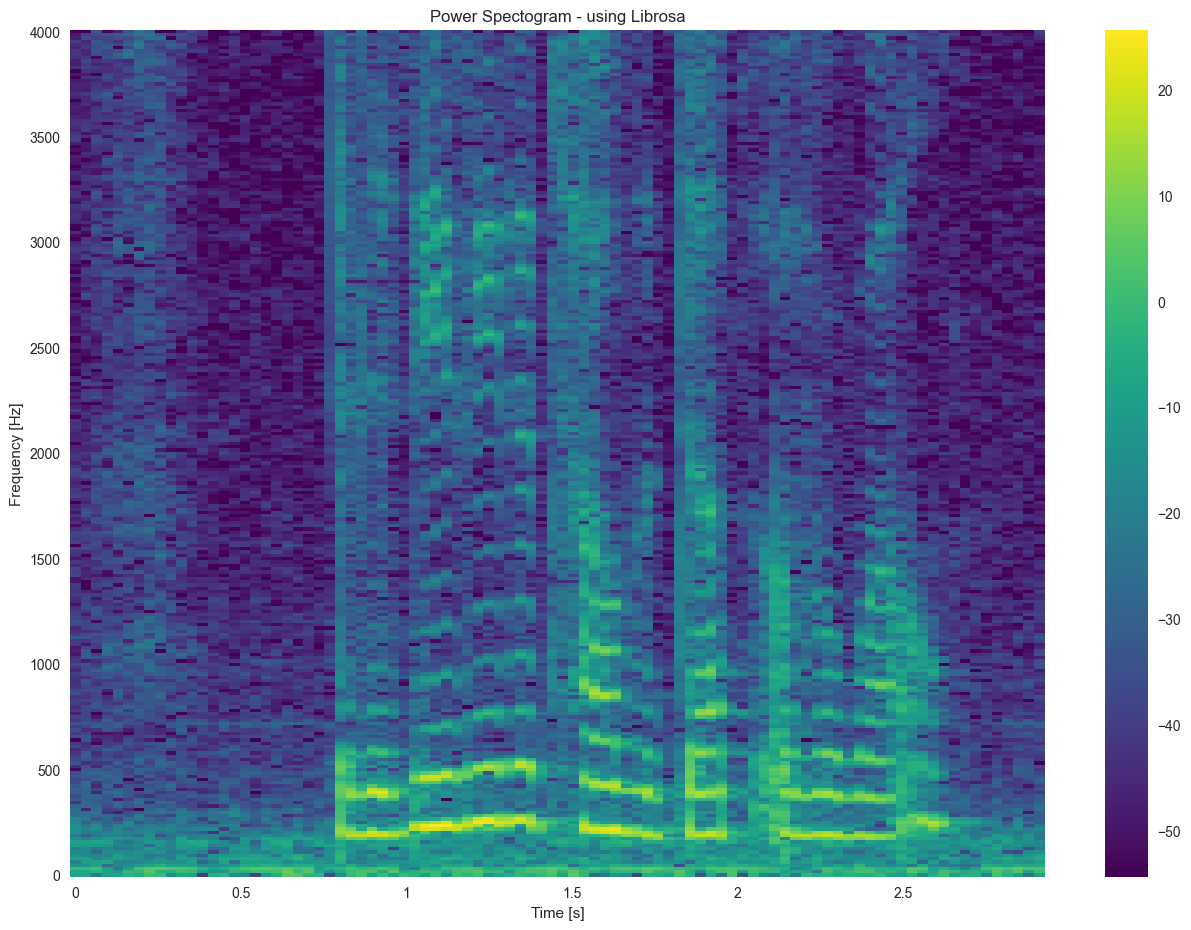

In [ ]:
# STFT and spectogram computation with libraries
X = librosa.stft(y=cut_audio, n_fft=frame_length, hop_length=hop_size)
X_pow_db = librosa.power_to_db(np.abs(X)**2)

w, h = plt.figaspect(0.7)
plt.figure(figsize=(w*2,h*2))
librosa.display.specshow(X_pow_db, sr=sample_rate, hop_length=hop_size, x_axis='time', y_axis='linear', cmap='viridis');
plt.colorbar()
plt.title('Power Spectrogram - using Librosa')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [s]')

* Experiment with different values of frame length and hop size and discuss the results.

In [ ]:
# original values: frame_length= 512   hop_size = 256
frame_length = 1024
hop_size = 128

print("Time bins: " +  str(np.ceil((len(cut_audio) - frame_length) / hop_size) + 1))
print("Frequency bins: " + str(frame_length//2 + 1))

X = librosa.stft(y=cut_audio, n_fft=frame_length, hop_length=hop_size)  # win_length = n_fft (default)
X_pow_db_2 = librosa.power_to_db(np.abs(X)**2)

w, h = plt.figaspect(0.7)
plt.figure(figsize=(w*2,h*2));
librosa.display.specshow(X_pow_db_2, sr=sample_rate, hop_length=hop_size, x_axis='time', y_axis='linear', cmap='viridis');
plt.colorbar()
plt.title(f'Power Spectrogram - different parameters (frame length {frame_length}, hop size {hop_size})')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [s]')

**Case 1 - Decrease the frame length and hop size to 1/4 of the original value**

WRITE YOUR CONCLUSIONS HERE!

**Case 2 - Increase the frame length and hop size to x2 of the original values**

WRITE YOUR CONCLUSIONS HERE!

**Case 3 - Increasing the frame length and decreasing the overlapping of frames simultaneously**

WRITE YOUR CONCLUSIONS HERE!

### **Exercise 5**: Mel-Spectrograms

Let's first check the librosa documentation: https://librosa.org/doc/main/generated/librosa.feature.melspectrogram.html

The most important parameters are 
  - **y** - audio sample vector ($x$)
  - **sr** - sampling rate of the audio signal (in Hz)
  - **n_mels** - number of Mel frequency bands (commonly: 64 or 128)
  - **win_length** - see above (STFT)
  - **hop_length** - see above (STFT)
  - **n_fft** - see above (STFT)

### Tasks:
* Compute the mel spectrogram using librosa. Experiment with different values of the parameters and discuss the results.

**Case 1 - Setting number of Mel bands to be generated as 40**

Take 40 mel bands is a typical number used as a best practice.

(40, 92)


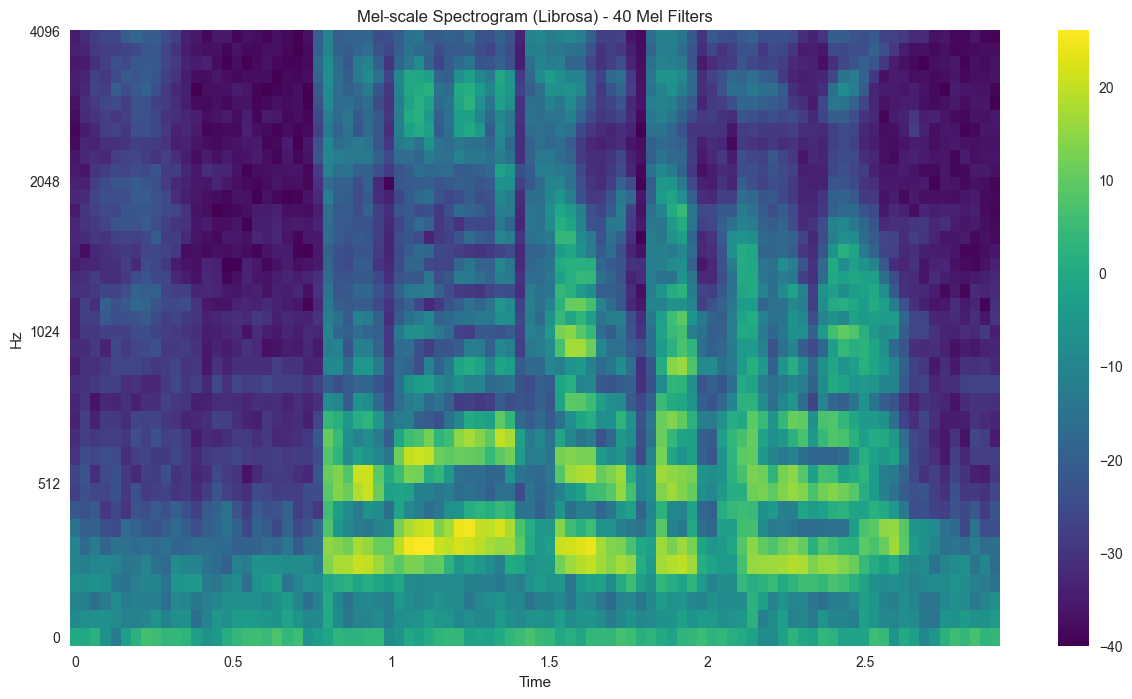

In [ ]:
# original values of frame length and hop size
frame_length = 512
hop_size = 256

# Mel spectogram parameter (number of bands) and computation
n_mels = 40
X_mel = librosa.feature.melspectrogram(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None) # win_length = n_fft (default)

plt.figure(figsize=(15,8));
librosa.display.specshow(librosa.power_to_db(X_mel), sr=sample_rate,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sample_rate/2, cmap='viridis');
plt.clim(-40,None);
plt.colorbar();
plt.title('Mel-scale Spectrogram (Librosa) - 40 Mel Filters');

**Case 2 - Decreasing number of Mel bands to 10**

In [ ]:
# Mel spectogram parameter (number of bands) and computation
n_mels = 10
X_mel_10 = librosa.feature.melspectrogram(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None) # win_length = n_fft (default)

plt.figure(figsize=(15,8));
librosa.display.specshow(librosa.power_to_db(X_mel_10), sr=sample_rate,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sample_rate/2, cmap='viridis');
plt.clim(-40,None);
plt.colorbar();
plt.title('Mel-scale Spectrogram (Librosa) - 10 Mel Filters');

WRITE YOUR CONCLUSIONS HERE!

### Now let's perform a similar analysis with a music signal ("oboe_c6.wav").


In [ ]:
!wget -P sample_data/ https://ccrma.stanford.edu/workshops/dsp2008/sound-library/oboe/Oboe1/Oboe-C6.wav

oboeC6 , sr = librosa.load('sample_data/Oboe-C6.wav', sr=None)
IPython.display.display(IPython.display.Audio(oboeC6, rate=sr))


**Case 1 - Setting number of Mel bands to be generated as 40**

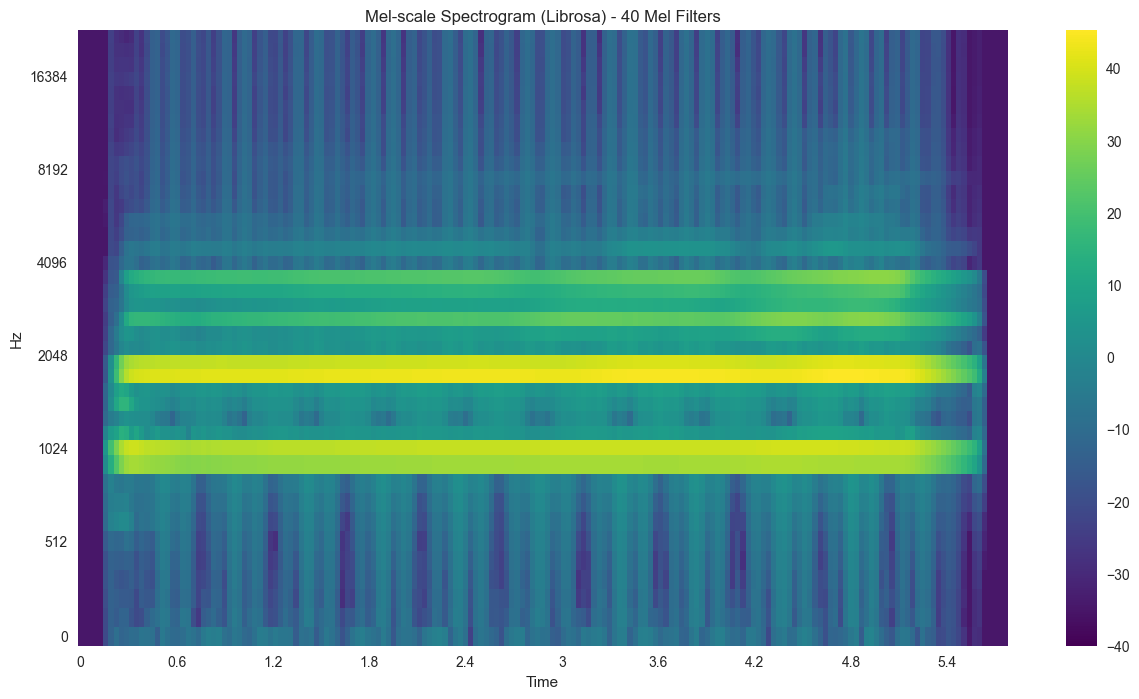

In [ ]:
# DEBUGGING

# STFT and spectogram computation with libraries
X_oboe = librosa.stft(y=oboeC6, n_fft=frame_length, hop_length=hop_size)
X_pow_db_oboe = librosa.power_to_db(np.abs(X_oboe)**2)

w, h = plt.figaspect(0.7)
plt.figure(figsize=(w*2,h*2))
librosa.display.specshow(X_pow_db_oboe, sr=sr, hop_length=hop_size,
                         x_axis='time', y_axis='linear', cmap='viridis');
plt.colorbar()
plt.title('Power Spectrogram - using Librosa')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [s]')

In [ ]:
# Mel spectogram parameter (number of bands) and computation
n_mels = 40
X_ob_mel = librosa.feature.melspectrogram(y=oboeC6, sr=sr,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None) # win_length = n_fft (default)

plt.figure(figsize=(15,8));
librosa.display.specshow(librosa.power_to_db(X_ob_mel), sr=sr,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sr/2, cmap='viridis');
plt.clim(-40,None);
plt.colorbar();
plt.title('Mel-scale Spectrogram (Librosa) - 40 Mel Filters');

**Case 2 - Decreasing number of Mel bands to 10**

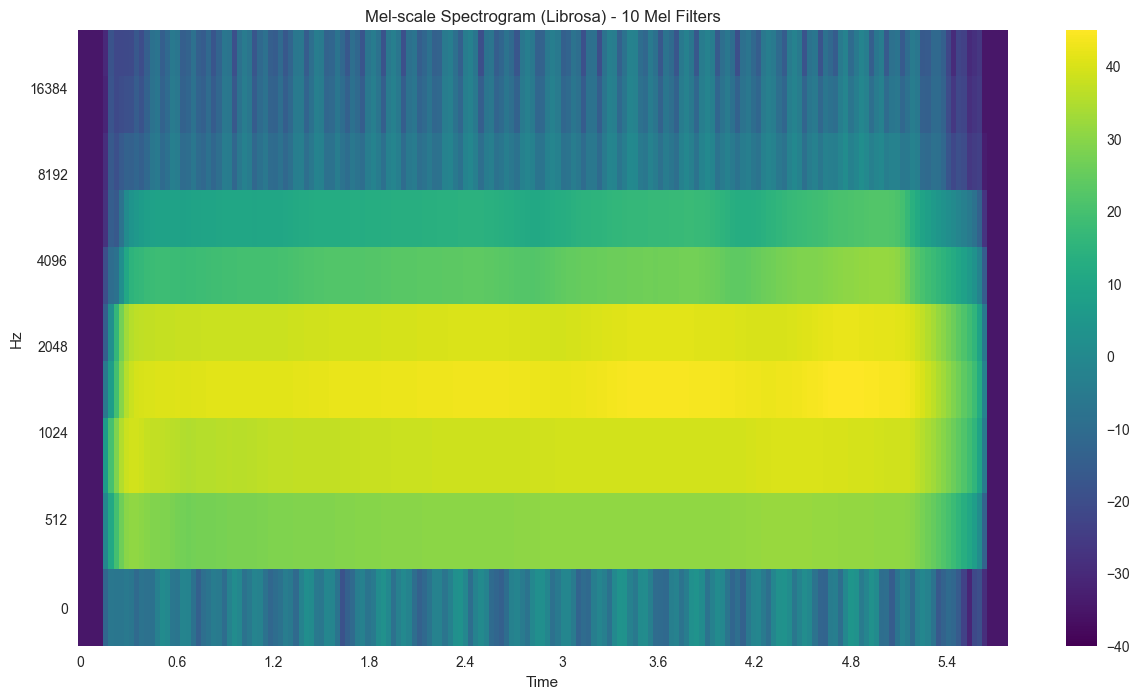

In [ ]:
# Mel spectogram parameter (number of bands) and computation
n_mels = 10
X_ob_mel_10 = librosa.feature.melspectrogram(y=oboeC6, sr=sr,
            n_fft=frame_length, hop_length=hop_size, n_mels=n_mels,
            power=2, norm=None) # win_length = n_fft (default)

plt.figure(figsize=(15,8));
librosa.display.specshow(librosa.power_to_db(X_ob_mel_10), sr=sr,
                         hop_length=hop_size, x_axis='time', y_axis='mel',
                         fmax=sr/2, cmap='viridis');
plt.clim(-40,None);
plt.colorbar();
plt.title('Mel-scale Spectrogram (Librosa) - 10 Mel Filters');

* Oboe analysis:

WRITE YOUR CONCLUSIONS HERE!

### **Exercise 6**: Constant-Q Transform

Let's first check the librosa documentation: https://librosa.org/doc/main/generated/librosa.cqt.html

The most important parameters are 
  - **y** - audio sample vector ($x$)
  - **sr** - sampling rate of the audio signal (in Hz)
  - **hop_length** - see above (STFT)
  - **f_min** - minimum frequency (we can use the default value of 32.70 Hz which corresponds to the note C1)
  - **n_bins** - total number of frequency bins (e.g., for a frequency resolution of one bin per semitone and 4 octaves, this would be 4 * 12 = 48)
  - **bins_per_octave** - Logarithmic frequency resolution (frequency bins per octave, commonly: 12 or 36)
  - **tuning** - Tuning offset (can be used if known tuning frequency of an audio recording deviates from 440 Hz) 

HINTS:

```Num of Octaves = n_bins / bins_per_octave```

```Max Frequency = fmin * 2**() n_bins / bins_per_octave```
  

### Tasks:
* Compute the constant Q transform using librosa.
Experiment with different values of the parameters and discuss the results.

**Case 1 - The default librosa.display.specshow parameter values.**

In [ ]:
# CQT parameters and computation
# fmin=librosa.note_to_hz('C1')
f_min = 32.70
n_octaves = 8
bins_octave = 12
n_bins = n_octaves * bins_octave
max_freq = f_min * 2**(n_bins/bins_octave)
C = librosa.cqt(y=oboeC6, sr=sr, hop_length=hop_size, fmin=f_min,
                     n_bins=n_bins, bins_per_octave=bins_octave)
logC = librosa.amplitude_to_db(C)

plt.figure(figsize=(15,8))
librosa.display.specshow(logC, sr=sr, x_axis='time', y_axis='cqt_note', cmap='viridis')
plt.colorbar()
plt.xlabel('Time [s]')
plt.title('Constant-Q Transform Power Spectrum')

**Case 2 - Limit the frequency range (fmin=Hz(C5)) -  increasing `bins_per_octave` to 24**

In [ ]:
# CQT parameters and computation
# fmin=librosa.note_to_hz('C5')
f_min = 32.70 * 2**(5-1)
n_octaves = 4
bins_octave = 24
n_bins = n_octaves * bins_octave
max_freq = f_min * 2**(n_bins/bins_octave)
C = librosa.cqt(y=oboeC6, sr=sr, hop_length=hop_size, fmin=f_min,
                     n_bins=n_bins, bins_per_octave=bins_octave)
logC = librosa.amplitude_to_db(C)

plt.figure(figsize=(15,8))
librosa.display.specshow(logC, sr=sr, x_axis='time', y_axis='cqt_note', cmap='viridis',
                         fmin=f_min, bins_per_octave=bins_octave)
plt.colorbar()
plt.xlabel('Time [s]')
plt.title('Constant-Q Transform Power Spectrum')

**Case 3 - Limit the frequency range (fmin=Hz(C5))- decrease the `n_bins` to 53**

In [ ]:
# CQT parameters and computation
# fmin=librosa.note_to_hz('C5')
f_min = 32.70 * 2**(5-1)
n_bins = 53
bins_octave = 12
n_octaves = n_bins / bins_octave
max_freq = f_min * 2**(n_bins/bins_octave)
C = librosa.cqt(y=oboeC6, sr=sr, hop_length=hop_size, fmin=f_min,
                     n_bins=n_bins, bins_per_octave=bins_octave)
logC = librosa.amplitude_to_db(C)

plt.figure(figsize=(15,8))
librosa.display.specshow(logC, sr=sr, x_axis='time', y_axis='cqt_note', cmap='viridis',
                         fmin=f_min, bins_per_octave=bins_octave)
plt.colorbar()
plt.xlabel('Time [s]')
plt.title('Constant-Q Transform Power Spectrum')

* CQT Analysis

WRITE YOUR CONCLUSIONS HERE!

### **Exercise 7**: MFCCs

Let's first check the librosa documentation: https://librosa.org/doc/latest/generated/librosa.feature.mfcc.html#librosa.feature.mfcc

The most important parameters are 
  - **y** - audio sample vector ($x$)
  - **sr** - sampling rate of the audio signal (in Hz)
  - **n_fft** - see above (STFT)
  - **hop_length** - see above (STFT)
  - **n_mfcc** - Number of MFC coefficients  

### Tasks:
* Compute MFCCs using librosa. Experiment with different values of the parameters and discuss the results.

**Case 1 - Using the standard librosa.feature.mfcc function on the audio file OSR_us_000_0010_8k.wav (seconds 7 to 10)**

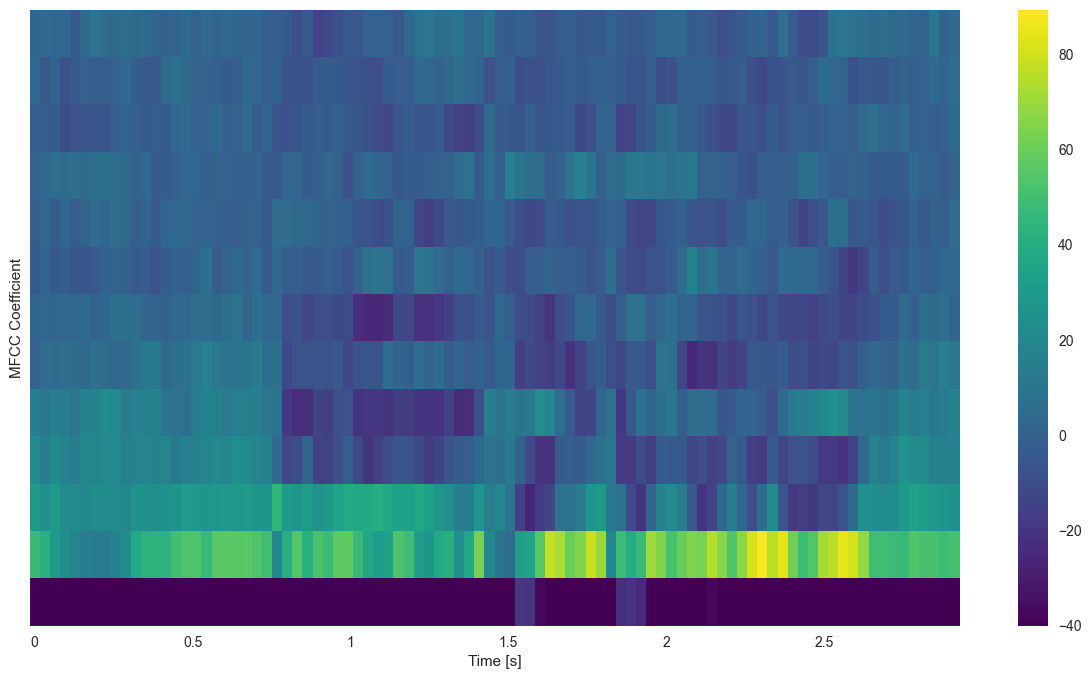

In [ ]:
# MFCC parameters and computation
X_mfcc = librosa.feature.mfcc(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, power=1, n_mfcc=13)

plt.figure(figsize=(15,8))
librosa.display.specshow(X_mfcc, sr=sample_rate, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time [s]')
plt.ylabel('MFCC Coefficient')

**Case 2 - Increasing the number of components to 40**



In [ ]:
# MFCC parameters and computation
X_mfcc = librosa.feature.mfcc(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, power=1, n_mfcc=40)

plt.figure(figsize=(15,8))
librosa.display.specshow(X_mfcc, sr=sample_rate, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time [s]')
plt.ylabel('MFCC Coefficient')

* WRITE YOUR CONCLUSIONS HERE!

**Case 3 - Changing the coefficient weighting parameter `lifter` to the number of 2 x number of cepstral coefficients**


In [ ]:
# MFCC parameters and computation
X_mfcc = librosa.feature.mfcc(y=cut_audio, sr=sample_rate,
            n_fft=frame_length, hop_length=hop_size, power=1,
            n_mfcc=40, lifter=2*40)

plt.figure(figsize=(15,8))
librosa.display.specshow(X_mfcc, sr=sample_rate, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time [s]')
plt.ylabel('MFCC Coefficient')

* WRITE YOUR CONCLUSIONS HERE!

**Case 4 - Comparing the oboe_c6.wav audio and simple_piano.wav sound**

In [ ]:
# MFCC parameters and computation
oboe_mfcc = librosa.feature.mfcc(y=oboeC6, sr=sr,
            n_fft=frame_length, hop_length=hop_size, power=1, n_mfcc=40)

plt.figure(figsize=(15,8))
librosa.display.specshow(oboe_mfcc, sr=sr, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time [s]')
plt.ylabel('MFCC Coefficient')

In [ ]:
!wget -P sample_data/ https://ccrma.stanford.edu/workshops/dsp2008/sound-library/piano/YamahaH/YamahaH-C6.wav

piano, sr_piano = librosa.load('sample_data/YamahaH-C6.wav', sr=None)
IPython.display.display(IPython.display.Audio(piano, rate=sr_piano))

# MFCC parameters and computation
piano_mfcc = librosa.feature.mfcc(y=piano, sr=sr_piano,
            n_fft=frame_length, hop_length=hop_size, power=1, n_mfcc=40)

plt.figure(figsize=(15,8))
librosa.display.specshow(piano_mfcc, sr=sr_piano, hop_length=hop_size,
                         x_axis='time', cmap='viridis')
plt.clim(-40,None)
plt.colorbar()
plt.xlabel('Time [s]')
plt.ylabel('MFCC Coefficient')

* WRITE YOUR CONCLUSIONS HERE!